# Level 2 – Task 2: Time Series Analysis
**Dataset:** Stock Prices (AAPL)  
**Tools:** Python, pandas, matplotlib, statsmodels

## 1. Load and Filter AAPL Data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import seasonal_decompose
import os

os.makedirs('plots', exist_ok=True)

df = pd.read_csv('../Data Set For Task/2) Stock Prices Data Set.csv')
aapl = df[df['symbol'] == 'AAPL'].copy()
aapl['date'] = pd.to_datetime(aapl['date'])
aapl.sort_values('date', inplace=True)
aapl.set_index('date', inplace=True)

print('Shape:', aapl.shape)
print('Date range:', aapl.index.min(), 'to', aapl.index.max())
aapl[['close']].head()

Shape: (1007, 6)
Date range: 2014-01-02 00:00:00 to 2017-12-29 00:00:00


,close
date,
2014-01-02,79.0185
2014-01-03,77.2828
2014-01-06,77.7042
2014-01-07,77.1481
2014-01-08,77.6371


## 2. Plot Raw Time Series

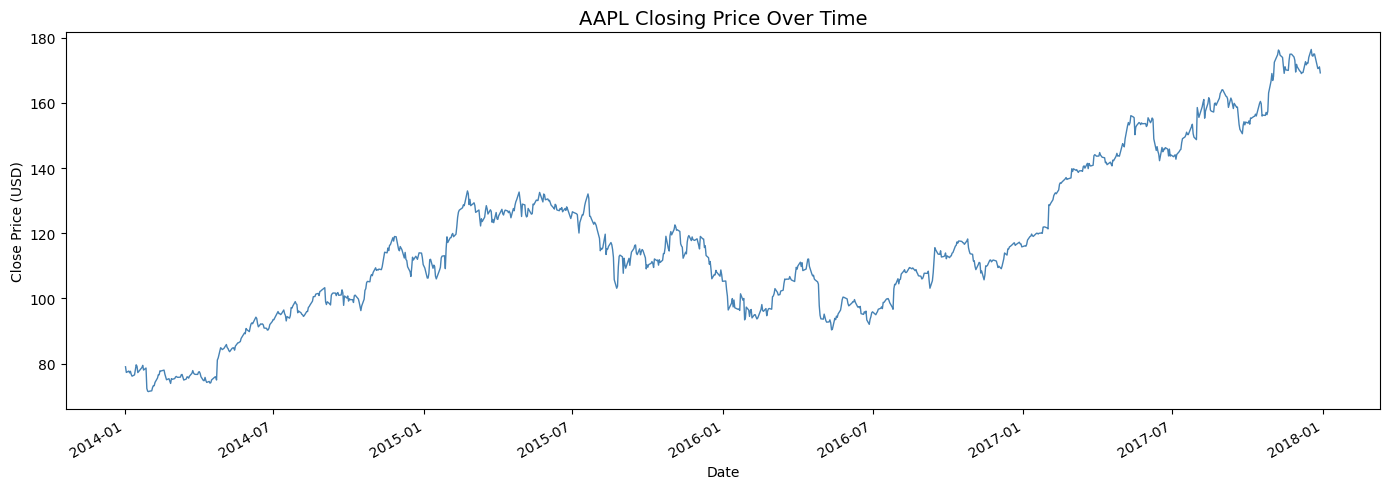

In [3]:
plt.figure(figsize=(14, 5))
plt.plot(aapl.index, aapl['close'], color='steelblue', linewidth=1)
plt.title('AAPL Closing Price Over Time', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Close Price (USD)')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.savefig('plots/aapl_raw.png', dpi=150)
plt.show()

## 3. Resample to Monthly and Identify Patterns

C:\Users\YSS\AppData\Local\Temp\ipykernel_20508\3759370094.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly = aapl['close'].resample('M').mean()


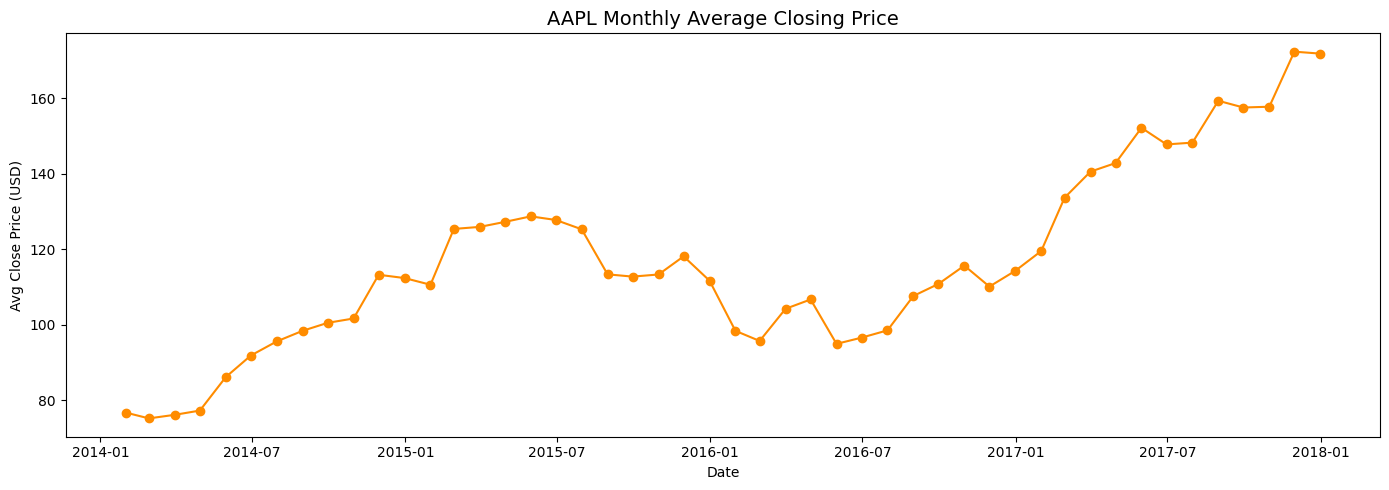

In [4]:
monthly = aapl['close'].resample('M').mean()

plt.figure(figsize=(14, 5))
plt.plot(monthly.index, monthly.values, marker='o', color='darkorange', linewidth=1.5)
plt.title('AAPL Monthly Average Closing Price', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Avg Close Price (USD)')
plt.tight_layout()
plt.savefig('plots/aapl_monthly.png', dpi=150)
plt.show()

## 4. Seasonal Decomposition
Decompose the monthly series into trend, seasonality, and residuals.

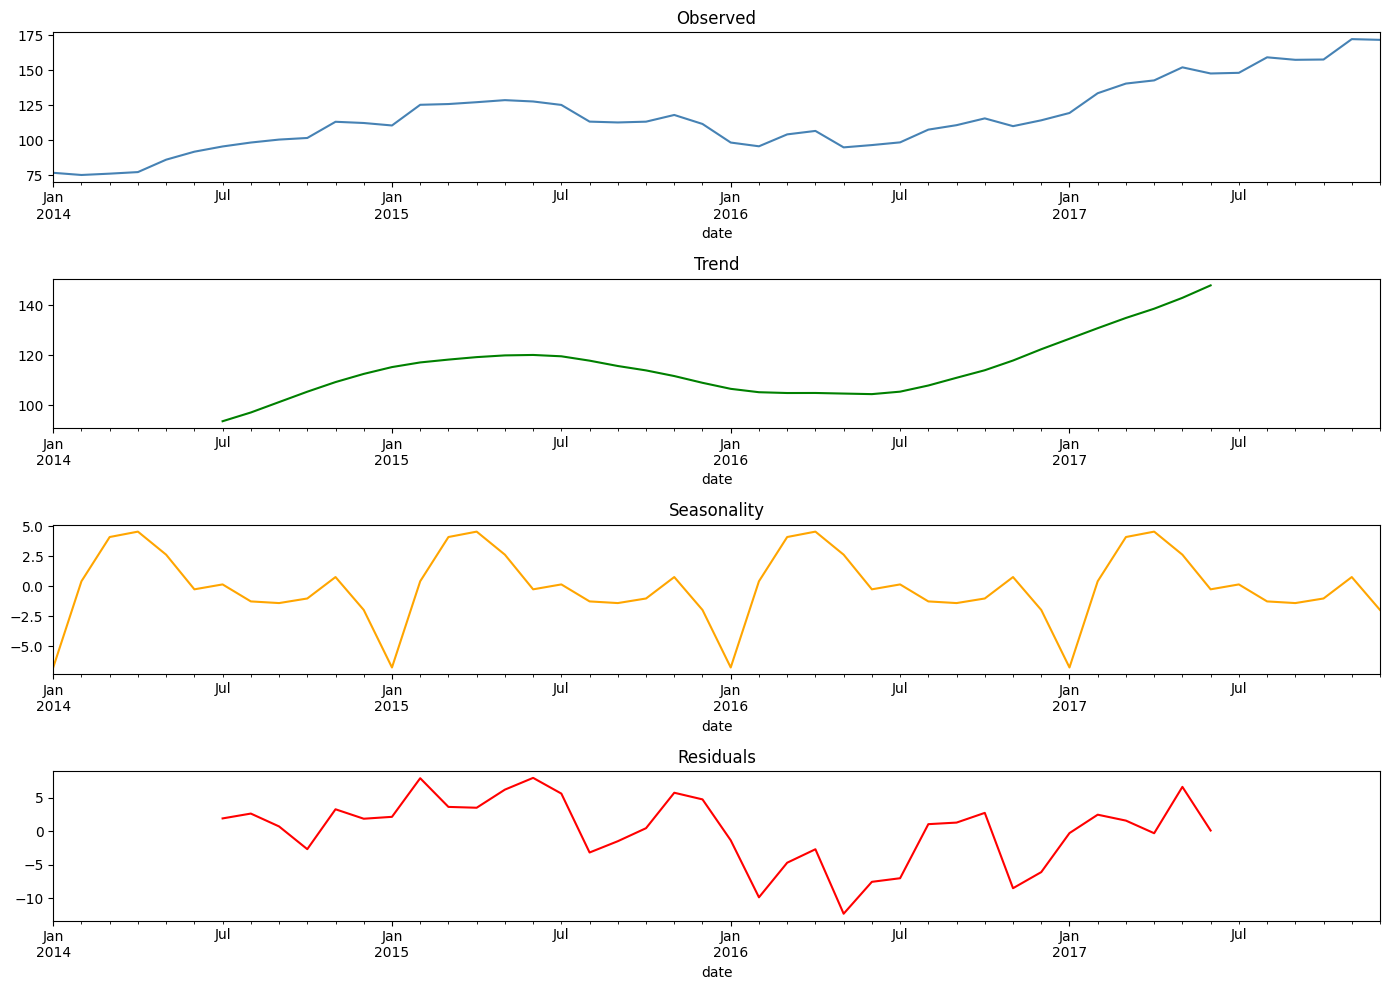

In [5]:
decomposition = seasonal_decompose(monthly, model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(14, 10))
decomposition.observed.plot(ax=axes[0], title='Observed', color='steelblue')
decomposition.trend.plot(ax=axes[1], title='Trend', color='green')
decomposition.seasonal.plot(ax=axes[2], title='Seasonality', color='orange')
decomposition.resid.plot(ax=axes[3], title='Residuals', color='red')

plt.tight_layout()
plt.savefig('plots/aapl_decomposition.png', dpi=150)
plt.show()

## 5. Moving Average Smoothing

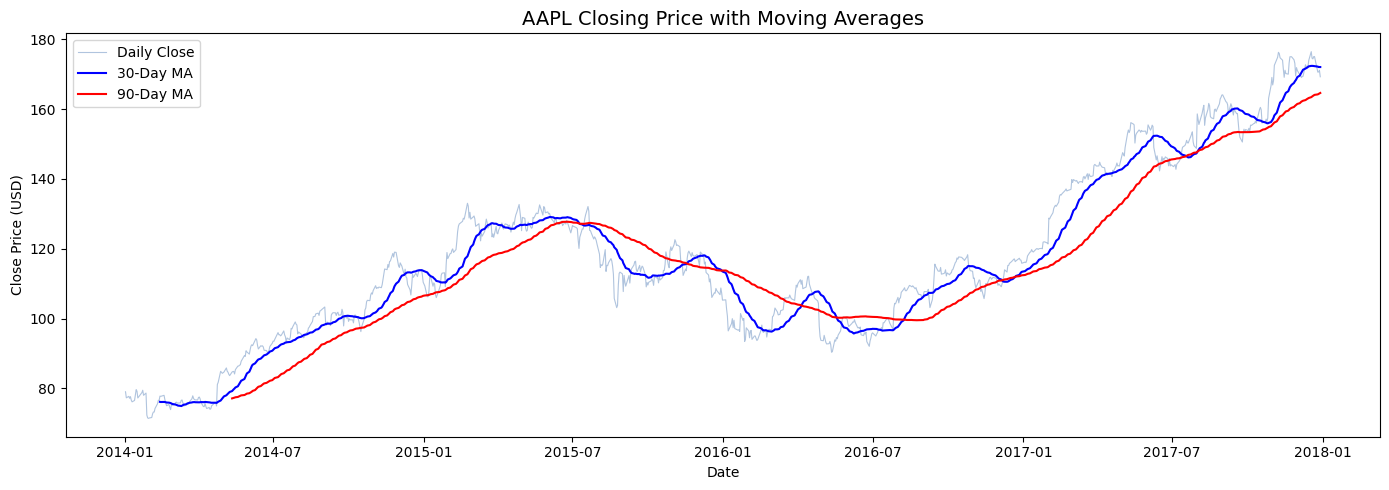

In [6]:
close = aapl['close']
ma30  = close.rolling(window=30).mean()
ma90  = close.rolling(window=90).mean()

plt.figure(figsize=(14, 5))
plt.plot(close.index, close, color='lightsteelblue', linewidth=0.8, label='Daily Close')
plt.plot(ma30.index, ma30, color='blue', linewidth=1.5, label='30-Day MA')
plt.plot(ma90.index, ma90, color='red', linewidth=1.5, label='90-Day MA')
plt.title('AAPL Closing Price with Moving Averages', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Close Price (USD)')
plt.legend()
plt.tight_layout()
plt.savefig('plots/aapl_moving_avg.png', dpi=150)
plt.show()

## Summary

| Analysis | Key Finding |
|----------|-------------|
| Raw Series | Clear upward trend in AAPL price over the period |
| Decomposition | Trend component confirms long-term growth; seasonality shows mild periodic patterns |
| Moving Averages | 30-day MA captures short-term momentum; 90-day MA shows the broader trend |